# 04 · Experimentos y gráficas finales

Este notebook responde las preguntas de los experimentos propuestos en el plan:

| Experimento | Pregunta | Cómo se corre |
|---|---|---|
| Umbral de densidad | ¿Con cuántos árboles deja de propagarse el fuego? | Runner de experimentos, `specs/umbral_densidad.toml` |
| Humedad | ¿Cómo cambia el área quemada entre temporada seca y lluviosa? | Runner, `specs/humedad.toml` |
| Viento | ¿Cómo cambia la propagación con viento despreciable, constante o variable? | Runner, `specs/viento.toml`, y mapas directos |
| Pendiente | ¿Cuánto más rápido sube que baja? | Escenas sintéticas (rampa y colina) |
| Cortafuegos y río | ¿Qué ancho evita que el fuego pase? | Escenas sintéticas (bosque con franja) |

Las escenas de relieve, río y cortafuegos de la Persona 3 todavía no existen. Por eso esos experimentos se hacen con escenas construidas aquí, directamente sobre el solver. Los demás usan el mismo runner headless que `pnpm experiments`, sobre la escena `flat`.

Las figuras se guardan en `analysis/figures/` y los resultados del runner en `analysis/results/experimentos/`.

In [1]:
import os
os.environ["FIRE_SIM_MODULE"] = "app.solver"  # must be set before importing app

import csv
import json
import sys
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

BACKEND = Path.cwd().parent
sys.path.insert(0, str(BACKEND))
from app.contracts import Scene, default_params
from app.mock.scenes import build_scene
from app.solver import create_simulation, param_specs
from experiments.run import run_experiment
from experiments.spec import load

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("results/experimentos"); RES.mkdir(parents=True, exist_ok=True)
DEFAULTS = default_params(param_specs())


def make_sim(scene, **overrides):
    return create_simulation(scene, DEFAULTS | overrides)


def run_until(sim, t_end, chunk=20):
    while sim.t < t_end and not sim.finished():
        sim.step(chunk)


def read_summary(name):
    with open(RES / name / "summary.csv", newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))


def grouped(rows, key, value):
    groups = defaultdict(list)
    for r in rows:
        groups[float(r[key])].append(float(r[value]))
    xs = np.array(sorted(groups))
    return xs, np.array([np.mean(groups[x]) for x in xs]), np.array([np.std(groups[x]) for x in xs])

## Corrida de los experimentos del runner

Se usan los mismos specs que `pnpm experiments`, en 4 procesos en paralelo.

In [2]:
for spec in ["umbral_densidad", "humedad", "viento"]:
    exp = load(BACKEND / "experiments" / "specs" / f"{spec}.toml")
    rows = run_experiment(exp, RES, jobs=4)
    print(f"{exp.name}: {len(rows)} corridas")

umbral_densidad: 24 corridas


humedad: 60 corridas


viento: 18 corridas


## 1. Umbral de densidad

En la escena `flat`, densidad 1 equivale a un árbol cada 10 celdas, con radios de copa entre 1 y 2.5 m. El combustible bajo las copas es 1 y el del suelo 0.4, por debajo del umbral de propagación. El fuego solo avanza si las copas están lo bastante juntas como para que el calor salte de una a otra.

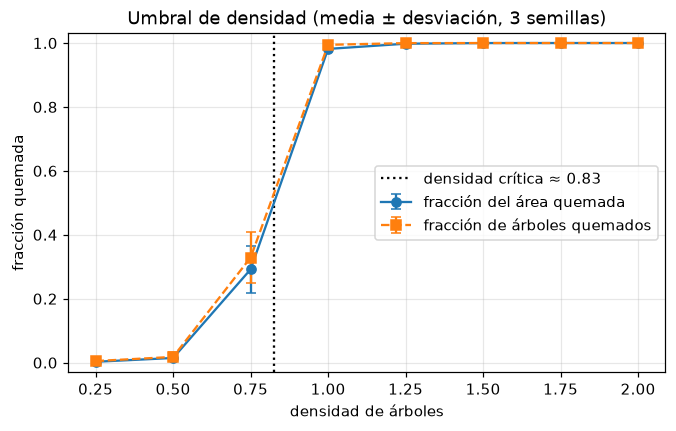

| densidad | área quemada | árboles quemados | velocidad media (m/s) |
|---|---|---|---|
| 0.25 | 0.3% ± 0.1% | 0.5% | 0.127 |
| 0.50 | 1.5% ± 1.1% | 1.8% | 0.172 |
| 0.75 | 29.2% ± 7.4% | 32.9% | 0.132 |
| 1.00 | 98.2% ± 0.4% | 99.5% | 0.285 |
| 1.25 | 99.8% ± 0.1% | 100.0% | 0.372 |
| 1.50 | 100.0% ± 0.0% | 100.0% | 0.398 |
| 1.75 | 100.0% ± 0.0% | 100.0% | 0.415 |
| 2.00 | 100.0% ± 0.0% | 100.0% | 0.434 |

In [3]:
dens = read_summary("umbral_densidad")
x, area, area_sd = grouped(dens, "scene.density", "burned_area_frac")
_, trees, trees_sd = grouped(dens, "scene.density", "burned_trees_frac")
_, speed, _ = grouped(dens, "scene.density", "front_speed_mean")

crit = None
above = np.nonzero(area >= 0.5)[0]
if above.size and above[0] > 0:
    i = above[0]
    crit = float(np.interp(0.5, [area[i - 1], area[i]], [x[i - 1], x[i]]))

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(x, area, yerr=area_sd, fmt="o-", capsize=3, label="fracción del área quemada")
ax.errorbar(x, trees, yerr=trees_sd, fmt="s--", capsize=3, label="fracción de árboles quemados")
if crit:
    ax.axvline(crit, color="k", ls=":", label=f"densidad crítica ≈ {crit:.2f}")
ax.set(xlabel="densidad de árboles", ylabel="fracción quemada", ylim=(-0.03, 1.03),
       title="Umbral de densidad (media ± desviación, 3 semillas)")
ax.legend(loc="center right")
fig.savefig(FIG / "umbral_densidad.png", bbox_inches="tight")
plt.show()

display(Markdown("| densidad | área quemada | árboles quemados | velocidad media (m/s) |\n|---|---|---|---|\n" + "\n".join(
    f"| {d:.2f} | {a:.1%} ± {s:.1%} | {t:.1%} | {v:.3f} |" for d, a, s, t, v in zip(x, area, area_sd, trees, speed))))

La transición es abrupta, como en un problema de **percolación**: por debajo de la densidad crítica el fuego se apaga cerca del punto de ignición, y por encima quema casi todo el bosque. Cerca del umbral, el resultado depende mucho de la semilla (barras de error grandes), porque decide si existe o no un camino continuo de copas.

Este es el comportamiento que predice el análisis del Bloque A: una celda aislada necesita β ≳ 0.125 para encenderse, pero el frente necesita β₀ ≳ 0.7 en promedio para sostenerse.

## 2. Humedad del combustible

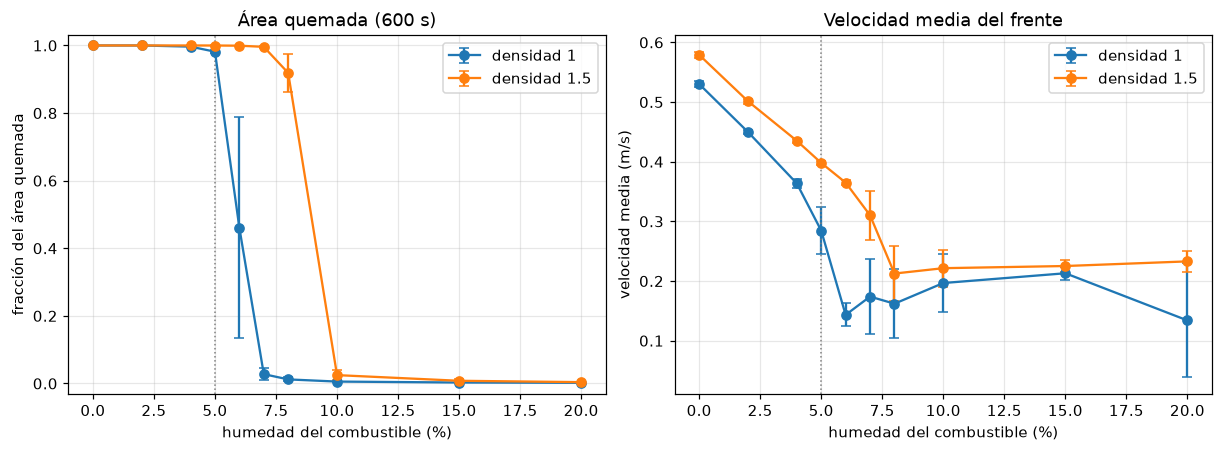

| densidad | humedad | área quemada | velocidad media (m/s) |
|---|---|---|---|
| 1 | 0% | 100.0% ± 0.0% | 0.530 |
| 1 | 2% | 100.0% ± 0.0% | 0.450 |
| 1 | 4% | 99.7% ± 0.0% | 0.364 |
| 1 | 5% | 98.2% ± 0.4% | 0.285 |
| 1 | 6% | 46.1% ± 32.7% | 0.143 |
| 1 | 7% | 2.8% ± 1.8% | 0.174 |
| 1 | 8% | 1.2% ± 0.6% | 0.162 |
| 1 | 10% | 0.6% ± 0.2% | 0.197 |
| 1 | 15% | 0.3% ± 0.0% | 0.213 |
| 1 | 20% | 0.2% ± 0.0% | 0.134 |
| 1.5 | 0% | 100.0% ± 0.0% | 0.579 |
| 1.5 | 2% | 100.0% ± 0.0% | 0.501 |
| 1.5 | 4% | 100.0% ± 0.0% | 0.435 |
| 1.5 | 5% | 100.0% ± 0.0% | 0.398 |
| 1.5 | 6% | 99.9% ± 0.0% | 0.365 |
| 1.5 | 7% | 99.6% ± 0.2% | 0.310 |
| 1.5 | 8% | 91.9% ± 5.7% | 0.213 |
| 1.5 | 10% | 2.5% ± 1.4% | 0.222 |
| 1.5 | 15% | 0.8% ± 0.4% | 0.225 |
| 1.5 | 20% | 0.4% ± 0.1% | 0.233 |

densidad 1: el fuego deja de propagarse desde 7% de humedad
densidad 1.5: el fuego deja de propagarse desde 10% de humedad


In [4]:
hum = read_summary("humedad")


def extinction_moisture(m, area):
    dead = np.nonzero(area < 0.05)[0]
    return float(m[dead[0]]) if dead.size else None


fig, ax = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
lines = ["| densidad | humedad | área quemada | velocidad media (m/s) |", "|---|---|---|---|"]
moisture_by_density = {}
for d in sorted({float(r["scene.density"]) for r in hum}):
    sub = [r for r in hum if float(r["scene.density"]) == d]
    m, h_area, h_sd = grouped(sub, "params.moisture", "burned_area_frac")
    _, h_speed, h_speed_sd = grouped(sub, "params.moisture", "front_speed_mean")
    moisture_by_density[d] = (m, h_area)
    ax[0].errorbar(m * 100, h_area, yerr=h_sd, fmt="o-", capsize=3, label=f"densidad {d:g}")
    ax[1].errorbar(m * 100, h_speed, yerr=h_speed_sd, fmt="o-", capsize=3, label=f"densidad {d:g}")
    lines += [f"| {d:g} | {v:.0%} | {a:.1%} ± {s_:.1%} | {sp:.3f} |"
              for v, a, s_, sp in zip(m, h_area, h_sd, h_speed)]
ax[0].set(xlabel="humedad del combustible (%)", ylabel="fracción del área quemada", ylim=(-0.03, 1.03),
          title="Área quemada (600 s)")
ax[1].set(xlabel="humedad del combustible (%)", ylabel="velocidad media (m/s)", title="Velocidad media del frente")
for a in ax:
    a.axvline(5, color="gray", ls=":", lw=1)
    a.legend()
fig.savefig(FIG / "humedad.png", bbox_inches="tight")
plt.show()
display(Markdown("\n".join(lines)))
for d, (m_, a_) in moisture_by_density.items():
    ext = extinction_moisture(m_, a_)
    print(f"densidad {d:g}: el fuego deja de propagarse desde " + (f"{ext:.0%}" if ext is not None else "más de 25 %") + " de humedad")

En temporada seca el fuego recorre casi todo el bosque. Al aumentar la humedad, el agua absorbe parte del calor (factor de Rothermel), así que el frente se frena hasta que deja de propagarse.

En un bosque con huecos entre copas, el fuego se apaga con mucha menos humedad que en combustible continuo, donde se sostenía hasta ≈22 % (Bloque C). Los dos efectos se suman: tanto la humedad como el espacio entre copas le restan calor al frente, así que basta poca humedad para dejarlo bajo el umbral de propagación. Además, un bosque más denso tolera más humedad antes de apagarse: con densidad 1.5 el fuego aguanta un par de puntos más de humedad que con densidad 1 (ver la humedad de extinción impresa arriba). Cerca de ese límite el resultado depende mucho de la semilla, igual que en el umbral de densidad.

## 3. Viento: despreciable, constante y variable

Encendemos en x = 60 m. El viento sopla hacia +x: 0° en los modos constante y variable.

In [5]:
win = read_summary("viento")
lines = ["| modo | U (m/s) | área quemada | velocidad media (m/s) |", "|---|---|---|---|"]
table = defaultdict(list)
for r in win:
    table[(int(float(r["params.wind_mode"])), float(r["params.wind_speed"]))].append(
        (float(r["burned_area_frac"]), float(r["front_speed_mean"])))
names = {0: "despreciable", 1: "constante", 2: "variable"}
for (mode, U), vals in sorted(table.items()):
    a = np.mean([v[0] for v in vals]); s = np.mean([v[1] for v in vals])
    lines.append(f"| {names[mode]} | {U:g} | {a:.1%} | {s:.3f} |")
display(Markdown("\n".join(lines)))

| modo | U (m/s) | área quemada | velocidad media (m/s) |
|---|---|---|---|
| despreciable | 2 | 96.9% | 0.269 |
| despreciable | 5 | 96.9% | 0.269 |
| despreciable | 10 | 96.9% | 0.269 |
| constante | 2 | 63.7% | 0.278 |
| constante | 5 | 50.4% | 0.301 |
| constante | 10 | 30.1% | 0.316 |
| variable | 2 | 61.2% | 0.267 |
| variable | 5 | 48.1% | 0.280 |
| variable | 10 | 33.2% | 0.330 |

El área quemada **baja** con viento porque, a los 400 s, el fuego ya llegó al borde de la escena a favor del viento y la cola, que avanza contra él, se apagó. La velocidad media (el crecimiento del radio equivalente) tampoco capta bien un fuego alargado. Para medir el efecto del viento seguimos directamente la **cabeza** (el punto quemado más a favor del viento) y la **cola** del incendio.

| modo | U (m/s) | velocidad de la cabeza (m/s) | avance de la cola a 150 s (m) |
|---|---|---|---|
| despreciable | 0 | 0.421 | 60 |
| constante | 2 | 0.609 | 14 |
| constante | 5 | 0.804 | 4 |
| constante | 10 | 1.132 | 2 |
| variable | 2 | 0.603 | 14 |
| variable | 5 | 0.786 | 2 |
| variable | 10 | 1.081 | 2 |

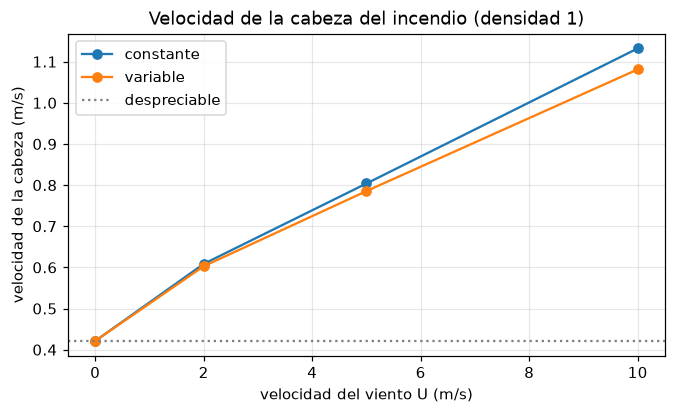

In [6]:
scene = build_scene("flat", 1.0, 0)
head_rows = []
for mode in (0, 1, 2):
    for U in ((0.0,) if mode == 0 else (2.0, 5.0, 10.0)):
        sim = make_sim(scene, wind_mode=mode, wind_speed=U, wind_dir=0.0)
        sim.ignite(60.0, 100.0, 3.0)
        ts, heads, tails = [], [], []
        while sim.t < 150 and not sim.finished():
            sim.step(20)
            cols = np.nonzero(sim._burned().any(axis=0))[0]
            if cols.size:
                ts.append(sim.t); heads.append(cols.max() + 0.5); tails.append(cols.min() + 0.5)
        ts, heads, tails = map(np.array, (ts, heads, tails))
        fit = (ts > 30) & (heads < 190)
        v_head = float(np.polyfit(ts[fit], heads[fit], 1)[0]) if fit.sum() > 3 else float("nan")
        head_rows.append((names[mode], U, v_head, 60.0 - tails[-1]))

display(Markdown("| modo | U (m/s) | velocidad de la cabeza (m/s) | avance de la cola a 150 s (m) |\n|---|---|---|---|\n" + "\n".join(
    f"| {n_} | {U:g} | {v:.3f} | {tail:.0f} |" for n_, U, v, tail in head_rows)))

fig, ax = plt.subplots(figsize=(7, 3.8))
calm = [r for r in head_rows if r[0] == "despreciable"][0][2]
for label in ("constante", "variable"):
    rows_ = [r for r in head_rows if r[0] == label]
    ax.plot([0] + [r[1] for r in rows_], [calm] + [r[2] for r in rows_], "o-", label=label)
ax.axhline(calm, color="gray", ls=":", label="despreciable")
ax.set(xlabel="velocidad del viento U (m/s)", ylabel="velocidad de la cabeza (m/s)",
       title="Velocidad de la cabeza del incendio (densidad 1)")
ax.legend()
fig.savefig(FIG / "viento_velocidad.png", bbox_inches="tight")
plt.show()

### Forma del área quemada

Mapas a los 200 s con U = 5 m/s sobre la misma escena (densidad 1, semilla 0).

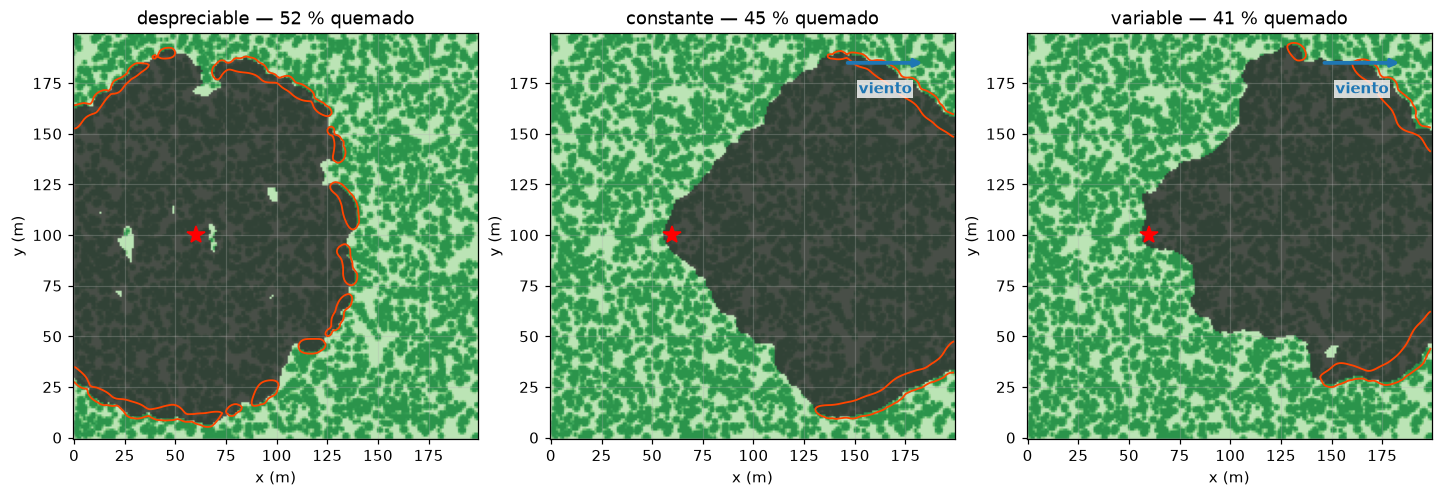

In [7]:
cases =[("despreciable", 0), ("constante", 1), ("variable", 2)]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), constrained_layout=True)
for ax, (label, mode) in zip(axes, cases):
    sim = make_sim(scene, wind_mode=mode, wind_speed=5.0, wind_dir=0.0)
    sim.ignite(60.0, 100.0, 3.0)
    run_until(sim, 200.0)
    burnt = np.where(sim._burned(), 1.0, np.nan)
    ax.imshow(sim.beta0, origin="lower", cmap="Greens", vmin=0, vmax=1.4)
    ax.imshow(burnt, origin="lower", cmap="Greys", vmin=0, vmax=1.2, alpha=0.85)
    ax.contour(sim.T, levels=[771], colors="orangered", linewidths=1.2)
    ax.plot(60, 100, "r*", ms=12)
    if mode:
        ax.annotate("", xy=(185, 185), xytext=(145, 185), arrowprops=dict(arrowstyle="-|>", lw=2.5, color="C0"))
        ax.text(165, 170, "viento", ha="center", color="C0", fontweight="bold",
                bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=1))
    ax.set(title=f"{label} — {sim.metrics()['burned_area'] / 400:.0f} % quemado", xlabel="x (m)", ylabel="y (m)")
fig.savefig(FIG / "viento_mapas.png", bbox_inches="tight")
plt.show()

- **Despreciable:** el área quemada crece aproximadamente en círculo, con bordes irregulares por la distribución de los árboles.
- **Constante:** el fuego se alarga a favor del viento (cabeza rápida) y casi no avanza en contra (cola). El viento precalienta el combustible de adelante y aleja el calor del de atrás.
- **Variable:** las ráfagas y el giro de dirección ensanchan la cabeza del incendio y hacen su avance más irregular.

## 4. Pendiente

Rampa $h = s\,x$ con combustible uniforme. Se enciende en el centro y, a los 50 s, se mide cuánto avanzó el fuego cuesta arriba (+x) y cuesta abajo (−x).

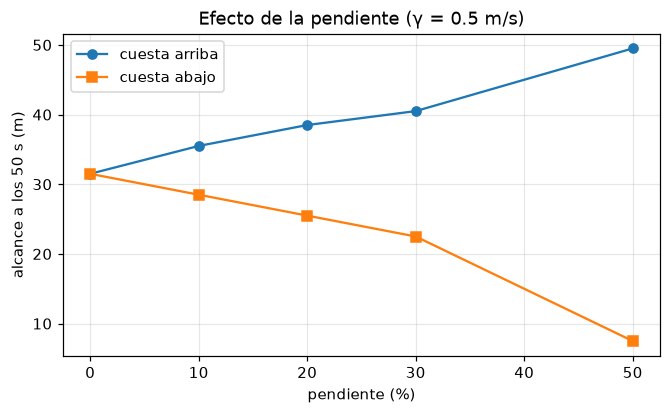

| pendiente | arriba (m) | abajo (m) | arriba/abajo |
|---|---|---|---|
| 0% | 32 | 32 | 1.00 |
| 10% | 36 | 28 | 1.25 |
| 20% | 38 | 26 | 1.51 |
| 30% | 40 | 22 | 1.80 |
| 50% | 50 | 8 | 6.60 |

In [8]:
def reach(sim, cx, cy):
    rows, cols = np.nonzero(sim._burned())
    return (cols + 0.5).max() - cx, cx - (cols + 0.5).min()

n = 120
slopes = [0.0, 0.1, 0.2, 0.3, 0.5]
slope_rows = []
for s in slopes:
    ramp = Scene(np.tile(s * np.arange(n, dtype=float), (n, 1)), 1.0, np.zeros((0, 4)))
    sim = make_sim(ramp, ground_fuel=1.0)
    sim.ignite(60.0, 60.0, 3.0)
    run_until(sim, 50.0)
    up, down = reach(sim, 60.0, 60.0)
    slope_rows.append((s, up, down))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot([s * 100 for s, *_ in slope_rows], [u for _, u, _ in slope_rows], "o-", label="cuesta arriba")
ax.plot([s * 100 for s, *_ in slope_rows], [d for *_, d in slope_rows], "s-", label="cuesta abajo")
ax.set(xlabel="pendiente (%)", ylabel="alcance a los 50 s (m)", title="Efecto de la pendiente (γ = 0.5 m/s)")
ax.legend()
fig.savefig(FIG / "pendiente.png", bbox_inches="tight")
plt.show()
display(Markdown("| pendiente | arriba (m) | abajo (m) | arriba/abajo |\n|---|---|---|---|\n" + "\n".join(
    f"| {s:.0%} | {u:.0f} | {d:.0f} | {u / d:.2f} |" for s, u, d in slope_rows)))

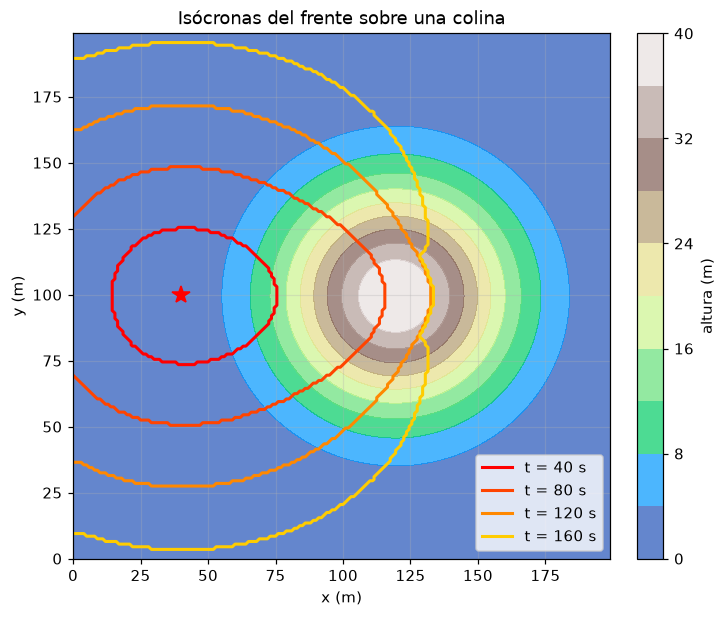

In [9]:
n = 200
yy, xx = np.mgrid[0:n, 0:n] + 0.5
hill = 40.0 * np.exp(-((xx - 120) ** 2 + (yy - 100) ** 2) / (2 * 30.0**2))
sim = make_sim(Scene(hill, 1.0, np.zeros((0, 4))), ground_fuel=1.0)
sim.ignite(40.0, 100.0, 3.0)
snapshots = []
for t_snap in (40, 80, 120, 160):
    run_until(sim, t_snap)
    snapshots.append(sim._burned().copy())

fig, ax = plt.subplots(figsize=(6.5, 5.5), constrained_layout=True)
cs = ax.contourf(hill, levels=12, cmap="terrain", alpha=0.7)
fig.colorbar(cs, ax=ax, label="altura (m)")
for snap, t_snap, col in zip(snapshots, (40, 80, 120, 160), plt.cm.autumn(np.linspace(0, 0.8, 4))):
    ax.contour(snap, levels=[0.5], colors=[col], linewidths=2)
    ax.plot([], [], color=col, lw=2, label=f"t = {t_snap} s")
ax.plot(40, 100, "r*", ms=12)
ax.set(title="Isócronas del frente sobre una colina", xlabel="x (m)", ylabel="y (m)")
ax.legend(loc="lower right")
fig.savefig(FIG / "colina_isocronas.png", bbox_inches="tight")
plt.show()

El fuego sube más rápido de lo que baja, y la diferencia crece con la pendiente. En la colina, las isócronas se aprietan en la ladera de bajada y se separan en la de subida: el frente la sube rápido, y al bajar por el otro lado se frena y queda rezagado respecto a los costados.

## 5. Cortafuegos y río: ancho crítico

Bosque denso (copas cada 2 m) con una franja sin árboles de ancho W en x = 60 m. Se enciende en x = 30 m.

- **Cortafuegos o claro:** la franja tiene el combustible del suelo (`ground_fuel` = 0.4).
- **Río:** la franja no tiene combustible (β₀ = 0).

Se repite sin viento y con viento hacia la franja, y se registra si el fuego aparece del otro lado.

| barrera | viento (m/s) | 0 m | 2 m | 4 m | 6 m | 8 m | 10 m | 12 m | 14 m | 16 m | 18 m | 20 m | 22 m | 24 m | ancho crítico |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| cortafuegos | 0 | cruza | cruza | cruza | · | · | · | · | · | · | · | · | · | · | 6 m |
| cortafuegos | 5 | cruza | cruza | cruza | cruza | cruza | cruza | cruza | cruza | · | · | · | · | · | 16 m |
| cortafuegos | 10 | cruza | cruza | cruza | cruza | cruza | cruza | cruza | cruza | cruza | cruza | cruza | cruza | cruza | > 24 m |
| río | 0 | cruza | · | · | · | · | · | · | · | · | · | · | · | · | 2 m |
| río | 5 | cruza | cruza | cruza | · | · | · | · | · | · | · | · | · | · | 6 m |
| río | 10 | cruza | cruza | cruza | cruza | cruza | · | · | · | · | · | · | · | · | 10 m |

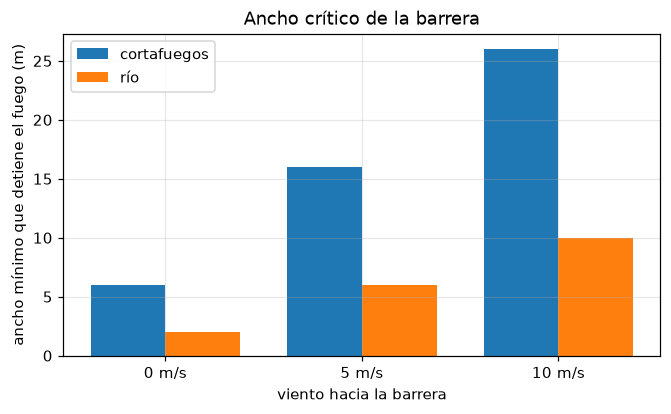

In [10]:
def forest_gap(width, n=120, x0=60):
    trees = [(cx, cy, 6.0, 1.5) for cy in np.arange(1.0, n, 2.0) for cx in np.arange(1.0, n, 2.0)
             if not x0 <= cx < x0 + width]
    return Scene(np.zeros((n, n)), 1.0, np.array(trees, np.float32).reshape(-1, 4))


def crosses(width, kind, wind):
    sim = make_sim(forest_gap(width), wind_mode=1 if wind else 0, wind_speed=float(wind), wind_dir=0.0)
    if kind == "río" and width > 0:
        sim.beta0[:, 60:60 + int(width)] = 0.0
        sim.beta[:] = sim.beta0
        sim._refresh_derived()
    sim.ignite(30.0, 60.0, 3.0)
    run_until(sim, 400.0)
    return bool(sim._burned()[:, int(60 + width) + 5:].any())


widths = list(range(0, 26, 2))
winds = [0, 5, 10]
results = {}
for kind in ("cortafuegos", "río"):
    for wind in winds:
        results[(kind, wind)] = [crosses(w, kind, wind) for w in widths]

critical = {}
for key, row in results.items():
    stopped = [w for w, c in zip(widths, row) if not c]
    critical[key] = stopped[0] if stopped else None

lines = ["| barrera | viento (m/s) | " + " | ".join(f"{w} m" for w in widths) + " | ancho crítico |",
         "|---|---|" + "---|" * len(widths) + "---|"]
for (kind, wind), row in results.items():
    crit_w = critical[(kind, wind)]
    lines.append(f"| {kind} | {wind} | " + " | ".join("cruza" if c else "·" for c in row) +
                 f" | {'> ' + str(widths[-1]) if crit_w is None else crit_w} m |")
display(Markdown("\n".join(lines)))

fig, ax = plt.subplots(figsize=(7, 3.8))
for i, kind in enumerate(("cortafuegos", "río")):
    vals = [critical[(kind, w)] if critical[(kind, w)] is not None else widths[-1] + 2 for w in winds]
    ax.bar(np.arange(len(winds)) + (i - 0.5) * 0.38, vals, 0.38, label=kind)
ax.set_xticks(range(len(winds)), [f"{w} m/s" for w in winds])
ax.set(xlabel="viento hacia la barrera", ylabel="ancho mínimo que detiene el fuego (m)",
       title="Ancho crítico de la barrera")
ax.legend()
fig.savefig(FIG / "cortafuegos.png", bbox_inches="tight")
plt.show()

- Sin viento basta una franja angosta: el calor que cruza por difusión no alcanza para encender el otro lado.
- Con viento hacia la barrera, el calor se transporta más lejos y **el ancho crítico crece rápidamente**. Por eso los cortafuegos reales se dimensionan según el viento esperado.
- Un río (sin combustible) detiene el fuego con menos ancho que un claro con pasto, porque el pasto todavía libera algo de calor dentro de la franja.

## Resumen

In [11]:
summary = {
    "critical_density": crit,
    "moisture_extinction": {f"{d:g}": extinction_moisture(m_, a_) for d, (m_, a_) in moisture_by_density.items()},
    "wind_head_speed": [{"mode": n_, "U": U, "head_m_s": v} for n_, U, v, _ in head_rows],
    "slope_reach": [{"slope": s, "up_m": float(u), "down_m": float(d)} for s, u, d in slope_rows],
    "critical_width_m": {f"{k}_{w}": critical[(k, w)] for (k, w) in critical},
}
(RES / "resumen.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps(summary, indent=2, ensure_ascii=False))

{
  "critical_density": 0.8254262170293488,
  "moisture_extinction": {
    "1": 0.07,
    "1.5": 0.1
  },
  "wind_head_speed": [
    {
      "mode": "despreciable",
      "U": 0.0,
      "head_m_s": 0.42111692749947777
    },
    {
      "mode": "constante",
      "U": 2.0,
      "head_m_s": 0.6085592185592094
    },
    {
      "mode": "constante",
      "U": 5.0,
      "head_m_s": 0.8039314516128984
    },
    {
      "mode": "constante",
      "U": 10.0,
      "head_m_s": 1.1322344322344164
    },
    {
      "mode": "variable",
      "U": 2.0,
      "head_m_s": 0.6028719211822651
    },
    {
      "mode": "variable",
      "U": 5.0,
      "head_m_s": 0.7855462184873787
    },
    {
      "mode": "variable",
      "U": 10.0,
      "head_m_s": 1.081176686217022
    }
  ],
  "slope_reach": [
    {
      "slope": 0.0,
      "up_m": 31.5,
      "down_m": 31.5
    },
    {
      "slope": 0.1,
      "up_m": 35.5,
      "down_m": 28.5
    },
    {
      "slope": 0.2,
      "up_m": 38.5,
 